# Quebec Startup Funding - Predicting Funding Round Size 

**Author:** Eglantine Dupuy 

**Data source:** Dealroom.co - a global data platform on tech ecosystems, startups and venture capital.

**Data set:** Funding rounds of Quebec-based companies dated 2021–present (exported 16/09/2026)

**Context:** I worked for almost 3 years at Dealroom.co as a Research Associate, essentially pulling funding data from the platform and doing analysis to investigate different startup sectors in order to publish and present market reports for stakeholders in the VC ecosystem. In my role I carried out all my analysis with Excel, I joined the program to become more technical and able to do larger scale analysis still related to the VC domain, as well as join specifically the Quebec VC market. This project is a good way, for me, to advance in both these goals.


## 1. Framing the Problem

**Business objective:** Understand what predicts the size of a startup funding round in Quebec. This is useful as a benchmarking tool e.g. a founder or investor comparing a prospective round to what similar Quebec companies have raised (not as a decision-making tool on its own).

**How the solution will be used:** As a descriptive/benchmarking model. Output is a predicted round amount to compare against.

**Current workarounds:** Investors and founders rely on personal deal comps and market experience; there's no simple public benchmarking tool for the Quebec market specifically. Though there are some paying ones such as Startup Montreal's platform powered and maintained by Dealroom.

**Framing:** Supervised learning, regression (the target round amount is continuous, not a category). We have a fixed historical dataset of past rounds, not a live streaming feed.

**Performance measure:** RMSE (root mean squared error), consistent with the reference notebook's use of RMSE for `median_house_value` and MAE as a secondary metric, since funding amounts are heavily right-skewed (a few mega-rounds), and RMSE is more sensitive to those outliers than MAE is.

**Comparable problems:** Similar to the reference notebook: predicting a continuous, skewed target from a mix of numeric and categorical features.

**Human expertise available:** Domain intuition from startup/VC experience.

### Methodology & Key Decisions

**Population definition.** The dataset is restricted to Quebec-HQ'd companies (HQ region/country/city on the *company*) funded between 2021 and today (16/09/2026), not Quebec-HQ'd investors. Filtering on the investor's HQ would answer "Where does Quebec capital flow?" but we are looking at what predicts funding round size for Quebec startups.

**Unit of analysis.** One row per funding round. Investor-level information (count, types, presence of a public/semi-public fund) is instead captured as aggregated features on the round-level row. 

**Target variable.** `Amount (USD M)` — the size of the funding round — rather than valuation. Valuation is disclosed far less often in this data (~50% missing vs. ~46% missing for round amount), so amount was chosen for better data coverage on the variable that actually needs to be predicted.

**Handling missing targets.** 45.6% of rows have no disclosed round amount. Critically, this missingness is *not* random: it's concentrated in Spinout (100% missing), unlabeled rounds (98%), Support Program (88%), Angel (41%), and Seed (30%) rounds, versus mostly-disclosed Series A–G rounds (0–12% missing). Rows with a missing target are dropped in code (not pre-filtered outside the notebook), so the exclusion is visible, reproducible, and its size and pattern can be reported. This means the modeling sample skews toward later-stage, better-disclosed rounds, a limitation stated explicitly here rather than left implicit.

**Government/semi-public investor feature.** Two engineered boolean features flag whether a round included a public or quasi-public investor has been semi-manually evaluated - using Dealroom's labeling of a "Sovreign wealth fund" and "Government non-profit" as well as adding in specific investors which were not originally labeled but are known to be publicly backed.  
- `Government Backed`: domestic (federal, Quebec provincial, or municipal) government bodies and Crown institutions — e.g. BDC Capital, Investissement Québec, Export Development Canada, Government of Quebec/Canada, National Research Council Canada, PME MTL.
- `Semi-Public`: institutional funds with a public mandate or tax-credit-backed structure, but that are not government agencies themselves, La Caisse (CDPQ), Fonds de solidarité FTQ, Fondaction.

**Note on interpretation.** `Government Backed` and `Semi-Public` are predictors, not proof of a causal effect. A high or low value for these flags shows an association within the model, not that government backing *causes* bigger or smaller rounds. Proving that would need a causal design, which is outside the scope of this project.

## 2. Data Acquisition

In [2]:
# Core libraries for data handling, numerical work, and plotting.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Keep plots readable and consistent in size for the whole notebook
plt.rc('font', size=12)
plt.rc('figure', figsize=(8, 5))

In [3]:
# Loading the Quebec funding-round export with the Government Backed / Semi-Public already 
# flagged manually in Excel, 1 means at least one Governmental fund is present in the round, 0 is the inverse, same for the semi-public column
from pathlib import Path

data_path = Path(r"C:\Users\eglan\OneDrive - McGill University\Desktop\VsCode_Sheets\EnterpriseDataScience\QuebecInvestmentRounds_fixed.csv")
df = pd.read_csv(data_path, header=3)

print(f"Loaded {df.shape[0]} rows and {df.shape[1]} columns")

Loaded 1141 rows and 40 columns


In [4]:
# First look at the raw structure of the data.

df.head()

,Name,ID,Dealroom URL,Website,Tagline,Long description,Growth stage,HQ region,HQ country,HQ city,...,Previous round type,Next round type,Downround,Peakround,Total rounds number,Valuation (USD) lower range,Valuation (USD) upper range,Average Valuation (USD),Technologies,Standardised round label
0,Onix,1,https://app.dealroom.co/companies/onix_2,http://onix.life,"Private, expert-driven AI for personalized wel...",Onix is a Montreal-based technology startup de...,early stage,North America,Canada,Montreal,...,NaN,NaN,NaN,NaN,1,20000000.0,30000000.0,25000000.0,NaN,SEED
1,EquiSoft,2,https://app.dealroom.co/companies/equisoft,http://equisoft.com,A global provider of software solutions for in...,Equisoft is a global provider of advanced digi...,late stage,North America,Canada,Montreal,...,GROWTH EQUITY VC,NaN,NaN,NaN,4,4000000.0,6000000.0,5000000.0,NaN,NaN
2,Fulltime AI,3,https://app.dealroom.co/companies/fulltime_ai,https://www.gofulltime.ai/,AI-powered front desk for home service busines...,Fulltime AI provides an AI-driven front desk s...,early stage,North America,Canada,Montreal,...,NaN,NaN,NaN,NaN,1,2933333.0,4400000.0,3666666.5,NaN,NaN
3,Scopia Surgical,4,https://app.dealroom.co/companies/scopia_surgical,http://scopia.tech,NaN,NaN,early stage,North America,Canada,Montreal,...,NaN,NaN,NaN,NaN,1,7773333.0,11660000.0,9716666.5,NaN,SEED
4,Telamont,5,https://app.dealroom.co/companies/telamont,http://telamont.com,AI-powered construction risk and contract mana...,Telamont provides an AI-powered software platf...,early stage,North America,Canada,Quebec City,...,NaN,NaN,NaN,NaN,1,NaN,NaN,0.0,artificial intelligence,NaN


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1141 entries, 0 to 1140
Data columns (total 40 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Name                         1141 non-null   object 
 1   ID                           1141 non-null   int64  
 2   Dealroom URL                 1141 non-null   object 
 3   Website                      1138 non-null   object 
 4   Tagline                      1125 non-null   object 
 5   Long description             1060 non-null   object 
 6   Growth stage                 1139 non-null   object 
 7   HQ region                    1141 non-null   object 
 8   HQ country                   1141 non-null   object 
 9   HQ city                      1096 non-null   object 
 10  Industries                   1074 non-null   object 
 11  Sub industries               579 non-null    object 
 12  Founding location            26 non-null     object 
 13  Tags              

In [6]:
# Distribution of a few key categorical columns, before deciding later how to encode them.

print(df["Growth stage"].value_counts(dropna=False))
print()
print(df["Round"].value_counts(dropna=False))
print()
print(df["HQ city"].value_counts(dropna=False).head(10))

Growth stage
early stage       812
breakout stage    253
late stage         74
NaN                 2
Name: count, dtype: int64

Round
SEED                    426
NaN                     125
EARLY VC                124
SUPPORT PROGRAM         105
SERIES A                 86
SPINOUT                  75
GROWTH EQUITY VC         43
LATE VC                  43
SERIES B                 36
PRIVATE PLACEMENT VC     18
ANGEL                    17
SERIES C                 17
CONVERTIBLE              14
SERIES D                  8
SERIES E                  2
SERIES G                  1
SERIES F                  1
Name: count, dtype: int64

HQ city
Montreal       801
Quebec City    112
Sherbrooke      47
NaN             45
Laval           30
Gatineau        18
Longueuil       14
Brossard        10
Westmount        8
Henryville       5
Name: count, dtype: int64


In [7]:
# Keeping only the columns useful for this analysis, and copying original data

cols_to_keep = [
    "Name", "ID", "Growth stage", "HQ city", "Industries", "Launch year",
    "Total amount raised (USD)", "Round", "Amount (USD M)", "Round valuation (USD)",
    "Average Valuation (USD)", "Year", "Month",
    "Government Backed", "Semi-Public", "Number of investors", "Total rounds number"
]

df_model = df[cols_to_keep].copy()

# Clearer names for the round date columns
df_model = df_model.rename(columns={
    "Year": "Round Year",
    "Month": "Round Month"
})

df_model.head()

,Name,ID,Growth stage,HQ city,Industries,Launch year,Total amount raised (USD),Round,Amount (USD M),Round valuation (USD),Average Valuation (USD),Round Year,Round Month,Government Backed,Semi-Public,Number of investors,Total rounds number
0,Onix,1,early stage,Montreal,health;enterprise software,2025.0,5000001,SEED,5.00,20000000-30000000,25000000.0,2026,9,0,0,4,1
1,EquiSoft,2,late stage,Montreal,fintech,1994.0,138000001,LATE VC,NaN,NaN,5000000.0,2026,9,0,0,1,4
2,Fulltime AI,3,early stage,Montreal,enterprise software,NaN,733334,SEED,0.73,2933333-4400000,3666666.5,2026,9,0,0,1,1
3,Scopia Surgical,4,early stage,Montreal,health,2024.0,1943334,SEED,1.94,7773333-11660000,9716666.5,2026,9,0,0,4,1
4,Telamont,5,early stage,Quebec City,real estate,2025.0,0,SEED,NaN,NaN,0.0,2026,8,0,0,1,1


In [8]:
df_model.shape 

#dropped from 40 to 17 columns

(1141, 17)

## 3. Data Exploration

In [9]:
# Summary stats for the numeric columns in our working table
df_model.describe()

,ID,Launch year,Total amount raised (USD),Amount (USD M),Average Valuation (USD),Round Year,Round Month,Government Backed,Semi-Public,Number of investors,Total rounds number
count,1141.000000,1114.000000,1.141000e+03,621.000000,1.141000e+03,1141.000000,1141.000000,1141.000000,1141.000000,1141.000000,1141.000000
mean,571.000000,2017.459605,2.088094e+07,14.469485,7.516464e+07,2022.718668,5.284838,0.152498,0.081507,1.926380,3.372480
std,329.522635,5.229390,6.562336e+07,33.680677,3.274268e+08,1.468587,3.539307,0.359660,0.273733,2.129949,2.643877
min,1.000000,1992.000000,0.000000e+00,0.000000,0.000000e+00,2021.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,286.000000,2016.000000,0.000000e+00,1.030000,0.000000e+00,2022.000000,2.000000,0.000000,0.000000,1.000000,1.000000
50%,571.000000,2019.000000,1.843053e+06,3.000000,5.133334e+06,2022.000000,5.000000,0.000000,0.000000,1.000000,3.000000
75%,856.000000,2021.000000,1.026667e+07,11.730000,3.625000e+07,2024.000000,8.000000,0.000000,0.000000,3.000000,5.000000
max,1141.000000,2026.000000,7.310000e+08,417.500000,5.000000e+09,2026.000000,12.000000,1.000000,1.000000,14.000000,18.000000


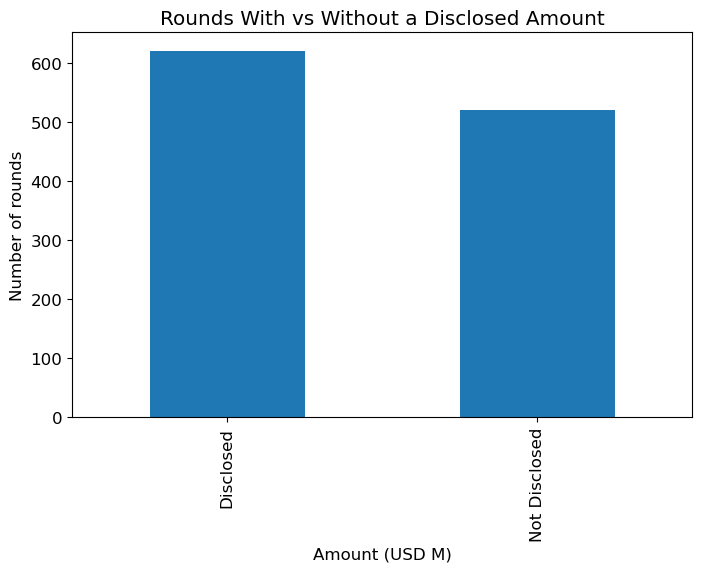

Amount (USD M)
Disclosed        621
Not Disclosed    520
Name: count, dtype: int64


In [10]:
# From industry and platform knowledge I know theres often a lot of undisclosed amount, 
# especially at early stages, lets visualize that

disclosed = df_model["Amount (USD M)"].notna()
disclosed_counts = disclosed.value_counts().rename({True: "Disclosed", False: "Not Disclosed"})

disclosed_counts.plot(kind="bar")
plt.ylabel("Number of rounds")
plt.title("Rounds With vs Without a Disclosed Amount")
plt.show()

print(disclosed_counts)

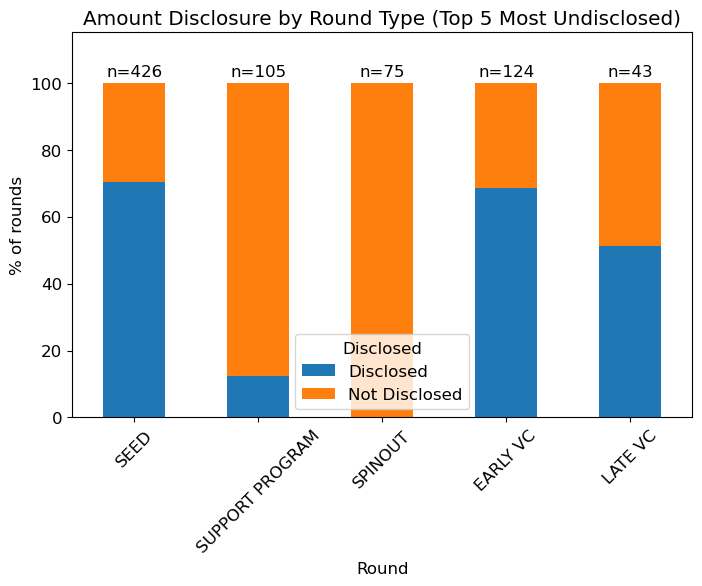

In [11]:
# Round types with the most undisclosed rounds, by count
undisclosed_by_round = df_model[df_model["Amount (USD M)"].isna()]["Round"].value_counts()
top_undisclosed_rounds = undisclosed_by_round.head(5).index

subset = df_model[df_model["Round"].isin(top_undisclosed_rounds)].copy()
subset["Disclosed"] = subset["Amount (USD M)"].notna().map({True: "Disclosed", False: "Not Disclosed"})

# Categories stay picked by count above -- only the bars themselves are shown as %
pct = pd.crosstab(subset["Round"], subset["Disclosed"], normalize="index") * 100
pct = pct.loc[top_undisclosed_rounds]  # keep sorted by undisclosed count

counts = subset["Round"].value_counts()

ax = pct.plot(kind="bar", stacked=True)
plt.ylabel("% of rounds")
plt.title("Amount Disclosure by Round Type (Top 5 Most Undisclosed)")
plt.xticks(rotation=45)

for i, round_type in enumerate(pct.index):
    plt.text(i, 102, f"n={counts[round_type]}", ha="center")

plt.ylim(0, 115)
plt.show()

confirmed that at early stages (early VC and seed, theres more undisclosed amounts). Spinouts and support program too (because really hard access, need partnerships with Unis who often don't even track this data). Support program missing values is slightly problematic for our analysis but it is not a very common round type, Governement backing now often happens under VC rounds, often co-invested with traditional fund types so it is an acceptable limitation. 

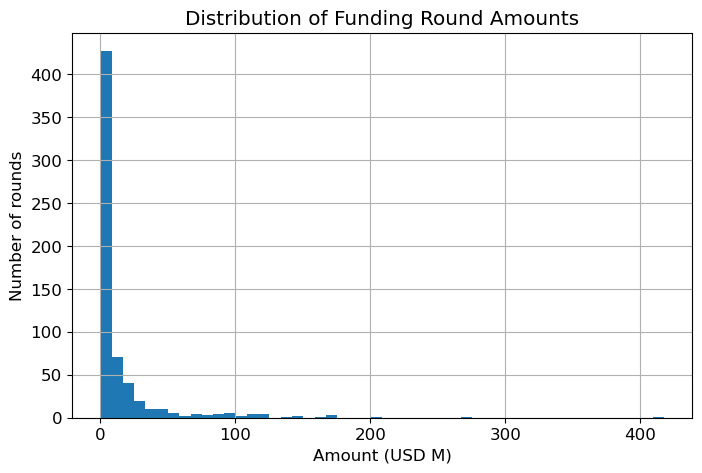

In [12]:
# How are funding round amounts distributed? Rounds without a disclosed amount are skipped here.

df_model["Amount (USD M)"].hist(bins=50)
plt.xlabel("Amount (USD M)")
plt.ylabel("Number of rounds")
plt.title("Distribution of Funding Round Amounts")
plt.show()

We see a concentration of early stage deals with a few large rounds.

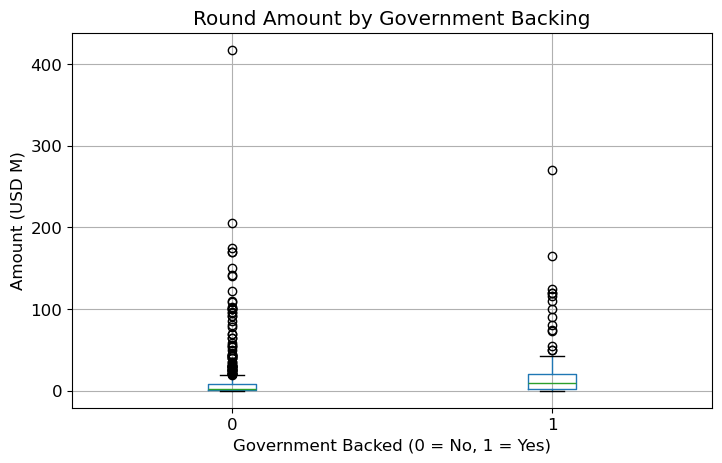

,count,mean,std,min,25%,50%,75%,max
Government Backed,,,,,,,,
0,476.0,12.604748,32.934288,0.0,0.73,2.235,8.31,417.5
1,145.0,20.590966,35.454870,0.0,2.50,10.000,20.00,270.0


In [13]:
# Round amount by government backing
df_model.boxplot(column="Amount (USD M)", by="Government Backed")
plt.xlabel("Government Backed (0 = No, 1 = Yes)")
plt.ylabel("Amount (USD M)")
plt.title("Round Amount by Government Backing")
plt.suptitle("")  # removes the default pandas subtitle
plt.show()

# Quick numbers to go with the chart
df_model.groupby("Government Backed")["Amount (USD M)"].describe()

We have 145 rounds with at least one governmental backer vs 476 with none. 
Government-backed rounds tend to be larger than non-government-backed ones. The median round size is $10.0M for government-backed rounds versus $2.2M for others — about 4.5x higher. 

We see that the average funding round amount is $20.6M for Quebecois startups backed by a public fund vs $12.6M for its inverse, about 1.6x.

The non-backed group contains one very large outlier round ($417.5M) that pulls its average up despite most non-backed rounds being small.

The non-backed group's box sits close to zero with a long tail of outliers, while the backed group's box is shifted noticeably higher, with a median around $10M.

It is important to note that we are not stating that having government backing causes larger rounds. A more likely explanation is that government and semi-public funds in this data tend to participate in later-stage or larger rounds rather than very early ones. Government are more risk averse and less involved in early stage rounds where VCs and other types of funds have the advantage to be specialized in, directly source investment deals sometimes even before MVP etc.

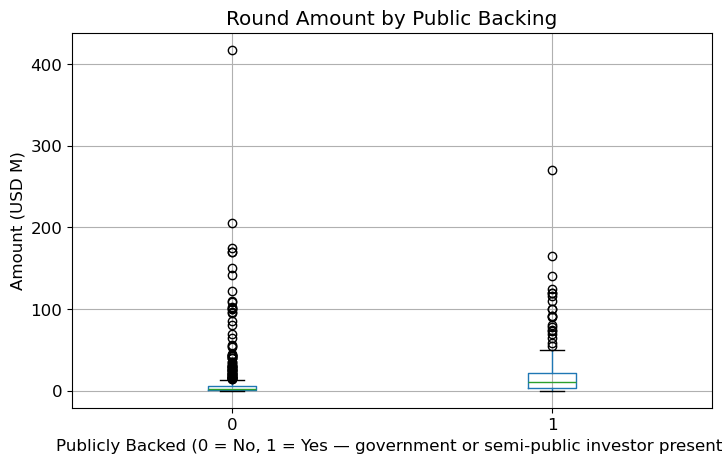

,count,mean,std,min,25%,50%,75%,max
Publicly Backed,,,,,,,,
0,445.0,11.234787,32.270489,0.0,0.590,2.1,6.0,417.5
1,176.0,22.648125,35.818355,0.0,2.845,11.0,22.0,270.0


In [14]:
#lets see what happens when we group government backed and semi-public funders too
# 1 = round had a government or semi-public investor, 0 = neither
df_model["Publicly Backed"] = ((df_model["Government Backed"] == 1) | (df_model["Semi-Public"] == 1)).astype(int)

df_model.boxplot(column="Amount (USD M)", by="Publicly Backed")
plt.xlabel("Publicly Backed (0 = No, 1 = Yes — government or semi-public investor present)")
plt.ylabel("Amount (USD M)")
plt.title("Round Amount by Public Backing")
plt.suptitle("")
plt.show()

df_model.groupby("Publicly Backed")["Amount (USD M)"].describe()

Combining government and semi-public backing into one group shows the same pattern as before, slightly more pronounced.
We can deduce there is 31 semi-publicly funded rounds in the dataset. Including them with Governement-backed hasn't shifted the Median round size much however the group's mean has increased by $2M.

The gap in the average of both groups is smaller ($22.6M vs. $11.2M, about 2.0x), likely due to the same large outlier round ($417.5M).

Overall this is suggesting that semi-public rounds tend to be sized similarly to, or even larger than, government-backed rounds on average, rather than sitting somewhere in between government and fully private.

## 4. Data Preparation

In [15]:
# removing rows without a disclosed amount to be able to train / evaluate a regression model
n_before = len(df_model)
df_model = df_model.dropna(subset=["Amount (USD M)"]).copy()
n_after = len(df_model)

print(f"Dropped {n_before - n_after} rows with no disclosed amount ({(n_before - n_after) / n_before:.1%})")
print(f"Remaining rows: {n_after}")

Dropped 520 rows with no disclosed amount (45.6%)
Remaining rows: 621


Handling outliers

In [ ]:
# finding the largest rounds in the data
df_model.nlargest(5, "Amount (USD M)")[["Name", "Round", "Round Year", "Amount (USD M)"]]

,Name,Round,Round Year,Amount (USD M)
165,5C Group,LATE VC,2025,417.5
763,Paper,SERIES D,2022,270.0
730,Enerkem,LATE VC,2022,205.0
949,Hopper,SERIES G,2021,175.0
298,Valsoft,GROWTH EQUITY VC,2024,170.0


they are not errors, they are just mega-rounds so we should keep them though they will greatly influence the results.

We will later employ multiple methods to protect against their effect: median imputation (not mean), stratified split on round size, a Random Forest that is fairly robust to extreme values, and MAE reported next to RMSE.

General round sizes buckets we used at Dealroom (and pretty consistent across industry):
* $100-250m+ (late stage)
* $40.0-100m (series C)
* $15.0-40.0m (series B)
* $4.0-15.0m (series A)
* $0-4.0m (seed)

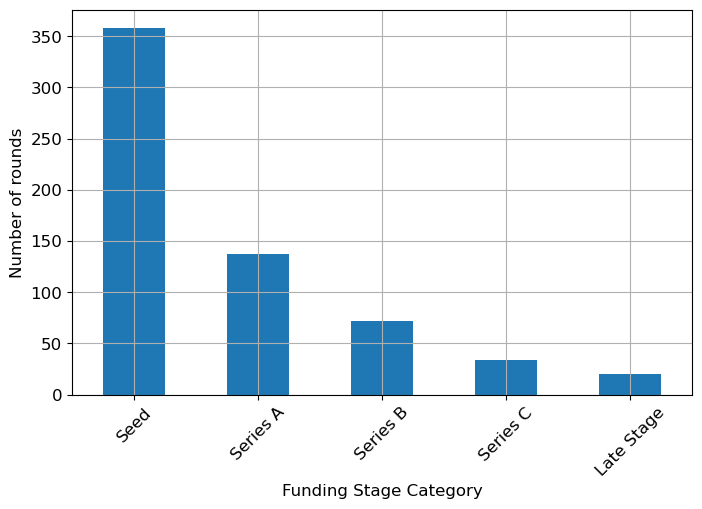

In [17]:
# splitting round amount into typical funding-stage ranges 
# Anything under $4M counts as Seed, anything over $100M (Series C's ceiling) counts as Late Stage
bins = [0, 4, 15, 40, 100, np.inf]
labels = ["Seed", "Series A", "Series B", "Series C", "Late Stage"]

df_model["amount_cat"] = pd.cut(df_model["Amount (USD M)"], bins=bins, labels=labels, include_lowest=True)

df_model["amount_cat"].value_counts().sort_index().plot.bar(rot=45, grid=True)
plt.xlabel("Funding Stage Category")
plt.ylabel("Number of rounds")
plt.show()

#from reference notebook

In [18]:
from sklearn.model_selection import train_test_split

train_set, test_set = train_test_split(
    df_model, test_size=0.2, stratify=df_model["amount_cat"], random_state=42
)

# Drop the helper column now that it's done its job
for set_ in (train_set, test_set):
    set_.drop("amount_cat", axis=1, inplace=True)

print(f"Train set: {len(train_set)} rows, Test set: {len(test_set)} rows")

#from reference notebook

Train set: 496 rows, Test set: 125 rows


Excluded from modeling:
- Name, ID: identifiers, not predictive
- Total amount raised (USD): includes this round's amount, so using it would leak the answer
- Round valuation (USD), Average Valuation (USD): mostly missing (~45-55%), too sparse to use here
- From now on going with "Publicly funded" which encompasses Government backed and semi-publicly funded

In [19]:
drop_cols = ["Name", "ID", "Total amount raised (USD)", "Round valuation (USD)", "Average Valuation (USD)",
             "Government Backed", "Semi-Public"]

X_train = train_set.drop(columns=["Amount (USD M)"] + drop_cols)
y_train = train_set["Amount (USD M)"].copy()

X_test = test_set.drop(columns=["Amount (USD M)"] + drop_cols)
y_test = test_set["Amount (USD M)"].copy()

X_train.head()

,Growth stage,HQ city,Industries,Launch year,Round,Round Year,Round Month,Number of investors,Total rounds number,Publicly Backed
414,early stage,Gatineau,real estate,2017.0,ANGEL,2023,5,1,7,0
999,early stage,NaN,health,2007.0,NaN,2021,6,0,4,0
114,late stage,Montreal,fashion;energy,2017.0,LATE VC,2025,5,4,9,1
769,late stage,Quebec City,transportation,2007.0,SERIES D,2022,2,10,17,1
1028,late stage,Quebec City,energy;transportation,2009.0,GROWTH EQUITY VC,2021,5,2,7,0


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

num_cols = ["Launch year", "Round Year", "Round Month", "Number of investors",
            "Total rounds number", "Publicly Backed"]
cat_cols = ["Growth stage", "HQ city", "Industries", "Round"]

# Numeric columns: fills missing values with the median, then scales
num_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

# Categorical columns: fills missing values with the most common category, then one-hot encode
cat_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore")),
])

preprocessing = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols),
])

X_train_prepared = preprocessing.fit_transform(X_train)
print(f"Shape after preprocessing: {X_train_prepared.shape}")

#from reference notebook

Shape after preprocessing: (496, 126)


### Feature engineering & preprocessing methods used

1. **Median imputation** (`SimpleImputer(strategy="median")`): missing numeric values are filled with the column median rather than the mean to avoid being dragged by outliers considering we are aware of some mega-rounds in the data.

2. **Standard scaling** (`StandardScaler`): rescales numeric features to mean 0 and std 1. This matters for linear regression but not for random forest.

3. **One-hot encoding** (`OneHotEncoder`): turns categories like HQ city and round type into 0/1 columns. `handle_unknown="ignore"` prevents a break on categories that aren't in the training data. And we are inputting missing values with the most frequent value.

## 5. Modeling

In [21]:
from sklearn.linear_model import LinearRegression

# Training a basic Linear Regression model on the training data
lin_reg = Pipeline([
    ("preprocessing", preprocessing),
    ("model", LinearRegression()),
])
lin_reg.fit(X_train, y_train)

# Check a few predictions against the real values
predictions = lin_reg.predict(X_train)
print("Predictions:", predictions[:5].round(1))
print("Actual:     ", y_train.iloc[:5].values)

#from reference notebook

Predictions: [-0.8  0.4 52.2 94.  48.9]
Actual:      [  1.49   2.69  40.   116.    29.33]


In [22]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

# Measure how far off the predictions are, on average
lin_rmse = root_mean_squared_error(y_train, predictions)
lin_mae = mean_absolute_error(y_train, predictions)
print(f"Training RMSE: {lin_rmse:.2f}")
print(f"Training MAE: {lin_mae:.2f}")

#from reference notebook

Training RMSE: 18.63
Training MAE: 8.57


In [23]:
from sklearn.tree import DecisionTreeRegressor

# Try a Decision Tree as an alternative model
tree_reg = Pipeline([
    ("preprocessing", preprocessing),
    ("model", DecisionTreeRegressor(random_state=42)),
])
tree_reg.fit(X_train, y_train)

tree_rmse = root_mean_squared_error(y_train, tree_reg.predict(X_train))
print(f"Decision Tree training RMSE: {tree_rmse:.2f}")

#from reference notebook

Decision Tree training RMSE: 0.00


A training RMSE of 0 means the unconstrained tree memorized the training set (overfitting). Its real performance is measured with cross-validation below.

In [24]:
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestRegressor

# Training error can be misleading (a model can just memorize the data),
# so use cross-validation to compare models more fairly
forest_reg = Pipeline([
    ("preprocessing", preprocessing),
    ("model", RandomForestRegressor(random_state=42)),
])

lin_rmses = -cross_val_score(lin_reg, X_train, y_train, scoring="neg_root_mean_squared_error", cv=5)
tree_rmses = -cross_val_score(tree_reg, X_train, y_train, scoring="neg_root_mean_squared_error", cv=5)
forest_rmses = -cross_val_score(forest_reg, X_train, y_train, scoring="neg_root_mean_squared_error", cv=5)

print("Linear Regression:\n", pd.Series(lin_rmses).describe())
print("\nDecision Tree:\n", pd.Series(tree_rmses).describe())
print("\nRandom Forest:\n", pd.Series(forest_rmses).describe())

#from reference notebook

Linear Regression:
 count     5.000000
mean     25.125837
std       7.917002
min      19.851928
25%      20.126169
50%      21.503008
75%      25.432317
max      38.715762
dtype: float64

Decision Tree:
 count     5.000000
mean     21.674629
std       6.671069
min      15.784940
25%      17.129696
50%      19.365066
75%      23.796628
max      32.296815
dtype: float64

Random Forest:
 count     5.000000
mean     20.994074
std       7.932348
min      15.389246
25%      15.979362
50%      16.393181
75%      23.213180
max      33.995402
dtype: float64


### Model Comparison

Random Forest and Decision Tree are performing noticeably better than plain Linear Regression here, which makes sense, round amounts don't move in a straight line with things like number of investors or launch year, so a tree-based model that can capture more complex patterns has an edge.

Random Forest performed best overall, with the lowest mean cross-validation RMSE ($20.99M), the lowest median ($16.39M), and the lowest minimum ($15.39M) among the three models tested. Decision Tree was a close second on average performance but more consistent across folds (lower standard deviation: 6.67 vs. 7.93 for Random Forest). Linear Regression was clearly the weakest, with the highest error on every measure — expected, since round amount likely doesn't scale in a simple straight-line way with the available features.

All three models show fairly high variability across folds (standard deviations of roughly 7-8, against means around 21-25), which reflects the modest size of the training set (~496 rows across 5 folds) and the inherent noisiness of funding data. 

Based on mean and median performance, Random Forest is selected as the model to move forward with.

## 6. Fine tuning our Random Forest Model

In [25]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

# Trying a range of values for a few key Random Forest settings
param_distribs = {
    "model__n_estimators": randint(low=50, high=300),
    "model__max_features": randint(low=2, high=20),
    "model__max_depth": randint(low=3, high=20),
}

rnd_search = RandomizedSearchCV(
    forest_reg, param_distributions=param_distribs, n_iter=10, cv=5,
    scoring="neg_root_mean_squared_error", random_state=42
)
rnd_search.fit(X_train, y_train)

print("Best parameters:", rnd_search.best_params_)
print("Best RMSE:", -rnd_search.best_score_)

#from reference notebook

Best parameters: {'model__max_depth': 17, 'model__max_features': 13, 'model__n_estimators': 104}
Best RMSE: 20.670946290618588


RMSE went from 20.99 (untuned) to 20.67, about a 1.5% improvement. Small gain but to be expected for a small, "noisy", dataset.

In [26]:
#evaluating this tuned model on the test set

final_model = rnd_search.best_estimator_
final_predictions = final_model.predict(X_test)

final_rmse = root_mean_squared_error(y_test, final_predictions)
final_mae = mean_absolute_error(y_test, final_predictions)

print(f"Test RMSE: {final_rmse:.2f}")
print(f"Test MAE: {final_mae:.2f}")

#from reference notebook

Test RMSE: 19.30
Test MAE: 7.56


In [32]:
# Training error of the final tuned model, to compare with the test error (overfitting check)
train_pred = final_model.predict(X_train)
train_rmse = root_mean_squared_error(y_train, train_pred)
train_mae = mean_absolute_error(y_train, train_pred)

print(f"Train RMSE: {train_rmse:.2f} | Test RMSE: {final_rmse:.2f}")
print(f"Train MAE:  {train_mae:.2f} | Test MAE:  {final_mae:.2f}")

Train RMSE: 8.43 | Test RMSE: 19.30
Train MAE:  3.59 | Test MAE:  7.56


The tuned Random Forest's test RMSE ($19.30M) is close to its CV RMSE ($20.67M) that's what indicates no overfitting, not the train/test gap. The low training RMSE ($8.43M) is expected: Random Forests fit training data very closely by nature, so it isn't a meaningful signal on its own.

Linear Regression underfit, with the highest CV RMSE of the three models, since round size doesn't follow a linear relationship.

The gap between RMSE ($19.30M) and MAE ($7.56M) reflects the target's skew, a few large rounds inflate RMSE more than MAE.

In [27]:
from scipy import stats

# 95% confidence interval for the test RMSE
confidence = 0.95
squared_errors = (final_predictions - y_test) ** 2
interval = np.sqrt(stats.t.interval(confidence, len(squared_errors) - 1,
                                     loc=squared_errors.mean(),
                                     scale=stats.sem(squared_errors)))
print(f"95% CI for test RMSE: {interval[0]:.2f} to {interval[1]:.2f}")

95% CI for test RMSE: nan to 29.54


C:\Users\eglan\AppData\Local\Temp\ipykernel_20472\3052848270.py:6: RuntimeWarning: invalid value encountered in sqrt
  interval = np.sqrt(stats.t.interval(confidence, len(squared_errors) - 1,


### Test Set Evaluation

The final tuned Random Forest model achieved a test RMSE of $19.30M and a test MAE of $7.56M. The test RMSE is slightly lower than the cross-validation RMSE (20.67), suggesting the model generalizes well rather than overfitting. The gap between RMSE and MAE reflects the same skew seen throughout the data, a few large prediction errors pull RMSE up more than MAE.

### Confidence Interval Note

A 95% confidence interval for the test RMSE returned NaN for the lower bound. This happens because the method assumes errors are normally distributed, but our errors are skewed, and with a small test set (~125 rows) the estimated lower bound went negative, impossible for a squared value. To fix this, we use a bootstrap confidence interval instead, which doesn't assume normality and avoids this issue.

In [28]:
# Bootstrap confidence interval for RMSE -- doesn't assume errors are normally distributed, since they are skewed
rng = np.random.default_rng(42)
n_boot = 1000
squared_errors = (final_predictions - y_test.values) ** 2

boot_rmses = [np.sqrt(rng.choice(squared_errors, size=len(squared_errors), replace=True).mean())
              for _ in range(n_boot)]

lower, upper = np.percentile(boot_rmses, [2.5, 97.5])
print(f"Bootstrap 95% CI for test RMSE: {lower:.2f} to {upper:.2f}")

Bootstrap 95% CI for test RMSE: 8.83 to 29.96


In [29]:
# Random Forest tracks which features it relied on most
importances = final_model.named_steps["model"].feature_importances_
feature_names = final_model.named_steps["preprocessing"].get_feature_names_out()

feat_importance = pd.Series(importances, index=feature_names).sort_values(ascending=False)
feat_importance.head(15)

#from reference notebook

cat__Growth stage_late stage                     0.198670
num__Launch year                                 0.099678
num__Total rounds number                         0.076364
cat__Industries_telecom                          0.074026
cat__Growth stage_early stage                    0.061135
cat__Round_LATE VC                               0.052923
num__Round Month                                 0.048674
num__Number of investors                         0.048084
num__Round Year                                  0.035096
cat__Growth stage_breakout stage                 0.030156
cat__Round_SEED                                  0.027433
cat__Industries_marketing;enterprise software    0.022996
cat__Round_GROWTH EQUITY VC                      0.020799
cat__Round_SERIES C                              0.016511
cat__Industries_travel;enterprise software       0.016178
dtype: float64

### Feature Importance

The most influential features were `Growth stage` (especially "late stage," the single strongest predictor), `Launch year`, `Total rounds number`, and `Round` type — all features describing where a company is in its funding lifecycle. Notably, `Publicly Backed` did not rank among the top 15 features, despite showing a large difference in the earlier boxplot comparison (median $11.0M vs. $2.1M).

This nuances that earlier finding rather than contradicting it: publicly backed rounds may simply tend to occur at later stages or after more prior rounds, both strong predictors on their own, rather than public backing itself being a major independent driver of round size. This is consistent with what we noted earlier: the boxplot showed an association, not a causal effect, and this feature importance result suggests a plausible mechanism for that association (stage and round timing, not backing itself).


In [30]:
import joblib

# Saving the final tuned model so it can be reused without retraining
joblib.dump(final_model, "quebec_funding_model.pkl")
print("Model saved.")

#from reference notebook

Model saved.


**Data source:** Dealroom.co. 

Retrieved from https://app.dealroom.co/. 

Query link (requires premium access): https://app.dealroom.co/transactions.rounds/f/growth_stages/not_mature/rounds/not_GRANT_SPAC%20PRIVATE%20PLACEMENT/slug_locations/anyof_~quebec_1~/tags/not_outside%20tech/years/anyof_2026_2025_2024_2023_2022_2021?showStats=YEAR&statsType=rounds

Filters down to technological companies headquartered in Quebec, Canada, with funding rounds dated 2021–2026. Exported on 16/09/2026.

Structure and several functions adapted from Aurélien Géron's end-to-end ML project notebook, Hands-On Machine Learning"  refered to as "Reference notebook" in multiple cells. 

## Conclusion

This project set out to predict the size of Quebec startup funding rounds (2021–present) from company and round characteristics, and to explore whether public or semi-public investor backing relates to round size. A tuned Random Forest model achieved a test RMSE of $19.30M (95% bootstrap CI: $8.83M–$29.96M) and MAE of $7.56M, outperforming both Linear Regression and an untuned Decision Tree.

The strongest predictors were growth stage, launch year, total rounds raised, and round type - features describing where a company sits in its funding lifecycle. Public/semi-public backing showed a clear association with larger rounds in a simple comparison (median $11.0M vs. $2.1M), but ranked low in the full model's feature importance, suggesting this association is largely explained by publicly backed rounds tending to occur at later stages, rather than public backing independently driving round size. This is consistent with the project's central caveat: the data supports predictive and associative conclusions, not causal ones, since there's no random assignment to public backing and no control region to isolate a policy effect.

**Key limitations:** 
* target missingness was substantial (~46%) and concentrated in early-stage/undisclosed round types, biasing the usable sample toward later-stage, better-documented rounds. The sample size (~621 disclosed rounds) is modest for a skewed target, contributing to the wide confidence interval on test RMSE. 
* largely right-skewed rounds in the data set. Most rounds are a few million dollars, but a handful are enormous so the model is minimizing error on those huge rounds at the expense of getting the much more common small/mid-size rounds right.
* perhaps too small of a test set (125)
* both growth stage and number of rounds are measured at export, not at the time of each round, this indicates a potential look-ahead leakage. 
* Industries encoding wasn't done well, combined strings created many near-empty columns so could not be useful for prediction.


**Potential next steps:** 
* a log-transform of the target could potentially better suit its skewed distribution 
* widening the analysis to a larger region or adding more years of data
* adding a comparable control region (e.g. Ontario) would enable a proper causal design around a specific, dated policy event, rather than the associative analysis done here;  
* Separating Government-backed from Semi-Public-backed rounds (rather than combining them) could reveal whether they behave differently.

## Launching, Monitoring and Maintenance

This model was built for analysis, not deployment, so no production launch is planned. If it were to be used on an ongoing basis, it would need periodic retraining as new rounds are disclosed (funding data is reported with a lag, so amounts for recent rounds fill in over time), and its assumptions should be re-checked periodically - particularly whether the missingness pattern by round type remains stable, since a shift there would affect how representative the training sample is.